# Data Science & AI/ML Practical Exam — Set A
## Campaign Response

**Objective:** Predict campaign responses and identify audience segments.

**Dataset:** `set_a.csv`

**Modules:**
1. Maths & Advanced Statistics
2. Data Preprocessing & Feature Engineering
3. Supervised Learning
4. Unsupervised Learning
5. Deep Learning — ANN


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings("ignore")


In [66]:
df = pd.read_csv(
    r"D:\set A- practical mock interview\data\raw\set_d.csv"
)

df.head()

,record_id,visits,recency,engagement,spend,group,response
0,1,53.96,43.84,54.57,58.93,G2,1
1,2,NaN,49.75,52.97,63.64,G2,1
2,3,35.39,66.52,44.98,47.33,G2,0
3,4,45.01,42.80,47.62,54.48,G1,1
4,5,53.84,53.72,48.33,58.30,G2,1


In [67]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nExact Duplicates:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["response"].value_counts())


Shape: (305, 7)

Columns:
['record_id', 'visits', 'recency', 'engagement', 'spend', 'group', 'response']

Data Types:
record_id       int64
visits        float64
recency       float64
engagement    float64
spend         float64
group          object
response        int64
dtype: object

Missing Values:
record_id      0
visits        16
recency       15
engagement     0
spend          0
group          0
response       0
dtype: int64

Exact Duplicates: 5

Target Distribution:
response
1    177
0    128
Name: count, dtype: int64


## Dataset Audit & Cleaning

The raw file has 305 rows, with 5 exact duplicate records.
The duplicates will be removed before creating the fit, validation and test partitions.

The original CSV is kept unchanged.


In [68]:
clean_df = df.drop_duplicates().copy()

print("Original shape:", df.shape)
print("Cleaned shape:", clean_df.shape)
print("Remaining duplicates:", clean_df.duplicated().sum())

Original shape: (305, 7)
Cleaned shape: (300, 7)
Remaining duplicates: 0


In [69]:
print("Unique record IDs:", clean_df["record_id"].nunique())

Unique record IDs: 300


## Train / Validation / Test Partition

After removing duplicate rows, the data is split into:
- 80% fit + validation data and 20% test data.
- 20% of the fit + validation portion is reserved for ANN validation.

Stratification is used for the response target and `random_state=42` is used for reproducibility.


In [70]:
development_set, test = train_test_split(clean_df, test_size=0.20, stratify=clean_df["response"], random_state=42)

fit, validation = train_test_split(development_set, test_size=0.20, stratify=development_set["response"], random_state=42)

print("Fit:", fit.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Fit: (192, 7)
Validation: (48, 7)
Test: (60, 7)


In [71]:
partition_index = pd.concat([fit[["record_id"]].assign(partition="fit"),
                       validation[["record_id"]].assign(partition="validation"),
                       test[["record_id"]].assign(partition="test")], 
                      ignore_index=True)

partition_index.to_csv("../outputs/splits.csv", index=False)

partition_index.head()

,record_id,partition
0,204,fit
1,123,fit
2,32,fit
3,289,fit
4,101,fit


In [72]:
# Verifying that partition IDs are unique and disjoint

print("Total partition IDs:", len(partition_index))
print("Unique partition IDs:", partition_index["record_id"].nunique())
print("Duplicate IDs:", partition_index["record_id"].duplicated().sum())

print("\nFit IDs:", fit["record_id"].nunique())
print("Validation IDs:", validation["record_id"].nunique())
print("Test IDs:", test["record_id"].nunique())

Total partition IDs: 300
Unique partition IDs: 300
Duplicate IDs: 0

Fit IDs: 192
Validation IDs: 48
Test IDs: 60


---

# Task 1 — Maths & Advanced Statistics

## M1 — Descriptive Statistics

We calculate descriptive statistics using the 192 fit records.
For `engagement`, observed values are used without imputation.


In [73]:
# Observed engagement values from the fit partition
observed_engagement = fit["engagement"].dropna()

n_engagement = observed_engagement.count()
mean_engagement = observed_engagement.mean()
median_engagement = observed_engagement.median()
std_engagement = observed_engagement.std(ddof=1)

print("Observed n : ", n_engagement)
print("Mean : ", mean_engagement)
print("Median : ", median_engagement)
print("Sample Standard Deviation : ", std_engagement)


Observed n :  192
Mean :  51.00182291666667
Median :  51.405
Sample Standard Deviation :  10.288960500356747


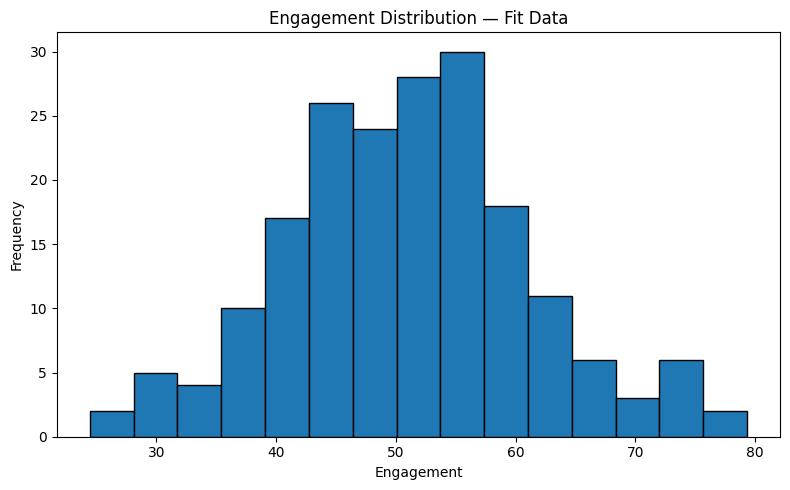

In [74]:
plt.figure(figsize=(8, 5))

plt.hist(observed_engagement, bins=15, edgecolor="black")
plt.title("Engagement Distribution — Fit Data")
plt.xlabel("Engagement")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("../outputs/figures/engagement_histogram.png", dpi=300)
plt.show()

**Interpretation:** The engagement values are mostly concentrated around 45–60, with a roughly bell-shaped distribution and a few higher values.

In [75]:
descriptive_summary = pd.DataFrame({"measure": ["observed_n", "mean", "median", "sample_std"],
                              "value": [n_engagement, mean_engagement, median_engagement, std_engagement]})

descriptive_summary.to_csv("../outputs/statistics_summary.csv", index=False)
descriptive_summary

,measure,value
0,observed_n,192.000000
1,mean,51.001823
2,median,51.405000
3,sample_std,10.288961


**Interpretation:**

- The observed fit data contains 192 engagement values because `engagement` has no missing values.
- The mean and median are close, so the centre of the observed engagement values is around 51.
- The histogram shows the spread of engagement values in the fit partition.


## M2 — Statistical Inference

We compare mean engagement between G1 and G2 using a two-sided Welch t-test at α = 0.05.

**H0:** The mean engagement is equal between G1 and G2.

**H1:** The mean engagement differs between G1 and G2.


In [76]:
g1_engagement = fit.loc[fit["group"] == "G1", "engagement"].dropna()
g2_engagement = fit.loc[fit["group"] == "G2", "engagement"].dropna()

# Welch's two-sided t-test
t_stat, p_value = stats.ttest_ind(g1_engagement, g2_engagement, equal_var=False)

print("G1 count : ", len(g1_engagement))
print("G2 count : ", len(g2_engagement))
print("Welch t-statistic : ", t_stat)
print("p-value : ", p_value)

alpha = 0.05
if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

G1 count :  84
G2 count :  108
Welch t-statistic :  0.7229961865721685
p-value :  0.47065078178032727
Decision: Fail to reject H0


In [77]:
# 95% CI for overall observed mean engagement

n = len(observed_engagement)
mean = observed_engagement.mean()
std = observed_engagement.std(ddof=1)

standard_error = std / np.sqrt(n)

t_critical = stats.t.ppf(0.975, df=n - 1)

margin_error = t_critical * standard_error

ci_lower = mean - margin_error
ci_upper = mean + margin_error

print("95% Confidence Interval : ")
print(f"({ci_lower:.4f}, {ci_upper:.4f})")

95% Confidence Interval : 
(49.5372, 52.4665)


In [78]:
test_summary = pd.DataFrame({"item": ["G1 count", "G2 count", "Welch t-statistic", "p-value", "alpha", "CI lower", "CI upper"],
                                  "value": [len(g1_engagement), len(g2_engagement), t_stat, p_value, alpha, ci_lower, ci_upper]})

test_summary.to_csv("../outputs/inference_results.csv", index=False)
test_summary

,item,value
0,G1 count,84.000000
1,G2 count,108.000000
2,Welch t-statistic,0.722996
3,p-value,0.470651
4,alpha,0.050000
5,CI lower,49.537188
6,CI upper,52.466458


**Interpretation:**

- The Welch t-test gives a p-value of approximately 0.471, which is greater than 0.05, so we fail to reject H₀.
- There is no statistically significant evidence of a difference in mean engagement between G1 and G2 in the fit data.
- The 95% confidence interval for the overall observed mean engagement is approximately 49.54 to 52.47.
- The test assumes independent observations and approximately normal sampling distributions.
- These results describe the synthetic observations and do not establish causation.


## M3 — Linear Algebra

We use fit records with observed values for both `engagement` and `visits`.

The two-column matrix is manually centered before calculating the sample covariance matrix. The largest eigenvalue represents the direction with the greatest variance.


In [79]:
paired_data = fit[["engagement", "visits"]].dropna()

X = paired_data.to_numpy()

# Manually center each column
X_mean = X.mean(axis=0)
centered_values = X - X_mean

print("Number of complete rows : ", len(X))
print("Column means : ", X_mean)
print("Centered matrix shape : ", centered_values.shape)

Number of complete rows :  181
Column means :  [51.08337017 49.4361326 ]
Centered matrix shape :  (181, 2)


In [80]:
# Sample covariance matrix
sample_covariance = (centered_values.T @ centered_values) / (len(centered_values) - 1)

print("Sample Covariance Matrix : ")
print(sample_covariance)

Sample Covariance Matrix : 
[[103.65708913   4.11811311]
 [  4.11811311 103.06117496]]


In [81]:
# Symmetric matrix eigenvalue calculation
eig_values, eig_vectors = np.linalg.eigh(sample_covariance)

# Sorting from largest to smallest
order = np.argsort(eig_values)[::-1]

eig_values = eig_values[order]
eig_vectors = eig_vectors[:, order]

largest_variance_share = eig_values[0] / eig_values.sum()

print("Eigenvalues : ", eig_values)
print("Largest eigenvalue : ", eig_values[0])
print("Largest variance share : ", largest_variance_share)
print("Largest variance share (%) : ", largest_variance_share * 100)

Eigenvalues :  [107.4880101   99.23025399]
Largest eigenvalue :  107.48801010083828
Largest variance share :  0.5199734555224486
Largest variance share (%) :  51.99734555224486


In [82]:
covariance_summary = pd.DataFrame(sample_covariance, index=["engagement", "visits"], columns=["engagement", "visits"])

covariance_summary.to_csv("../outputs/covariance_matrix.csv")

eigenvalue_table = pd.DataFrame({"eigenvalue": eig_values, 
                                 "variance_share": eig_values / eig_values.sum()})

eigenvalue_table.to_csv("../outputs/eigenvalues.csv", index=False)
eigenvalue_table

,eigenvalue,variance_share
0,107.488010,0.519973
1,99.230254,0.480027


**Interpretation:**

- The largest eigenvalue is approximately 107.49 and explains about 52.00% of the total variance.
- Its corresponding eigenvector represents the principal direction of greatest variation in the engagement and visits feature space.


---

# Task 2 — Data Preprocessing & Feature Engineering

## F1 — Audit and Partition

The cleaned dataset contains 300 unique records after removing the 5 exact duplicates.

The required partition sizes are:
- Fit: 192 records
- Validation: 48 records
- Test: 60 records

The partition IDs were saved in `outputs/splits.csv` and checked for duplicates.


In [83]:
numeric_features = ["visits", "recency", "engagement", "spend"]
categorical_features = ["group"]

target = "response"
id_column = "record_id"

# Separating predictors and target
X_fit = fit.drop(columns=[target, id_column]).copy()
X_val = validation.drop(columns=[target, id_column]).copy()
X_test = test.drop(columns=[target, id_column]).copy()

y_fit = fit[target].copy()
y_val = validation[target].copy()
y_test = test[target].copy()

print("Fit predictors : ", X_fit.shape)
print("Validation predictors : ", X_val.shape)
print("Test predictors : ", X_test.shape)

Fit predictors :  (192, 5)
Validation predictors :  (48, 5)
Test predictors :  (60, 5)


## F2 — Transform and Engineer

Numeric missing values are handled using median imputation, with medians learned only from the fit partition.

The required engineered feature is:

`engineered_feature = engagement / (recency + 1)`

It is created after imputation and before scaling.

Numeric features are standardized using parameters learned only from the fit partition. The one-hot encoded `group` columns remain unscaled.


In [84]:
median_imputer = SimpleImputer(strategy="median")

# Fit only on the 192 fit records
X_fit_numeric_imputed = pd.DataFrame(median_imputer.fit_transform(X_fit[numeric_features]), columns=numeric_features, index=X_fit.index)

# Transform validation/test using the same fitted imputer
X_val_numeric_imputed = pd.DataFrame(median_imputer.transform(X_val[numeric_features]), columns=numeric_features, index=X_val.index)


X_test_numeric_imputed = pd.DataFrame(median_imputer.transform(X_test[numeric_features]), columns=numeric_features, index=X_test.index)

print("Fit medians : ")
print(pd.Series(median_imputer.statistics_, index=numeric_features))

Fit medians : 
visits        49.610
recency       50.600
engagement    51.405
spend         50.595
dtype: float64


In [85]:
# Creating engineered feature after imputation, before scaling

X_fit_numeric_imputed["engineered_feature"] = (X_fit_numeric_imputed["engagement"] / (X_fit_numeric_imputed["recency"] + 1))
X_val_numeric_imputed["engineered_feature"] = (X_val_numeric_imputed["engagement"] / (X_val_numeric_imputed["recency"] + 1))
X_test_numeric_imputed["engineered_feature"] = (X_test_numeric_imputed["engagement"] / (X_test_numeric_imputed["recency"] + 1))

print(X_fit_numeric_imputed.head())

     visits  recency  engagement  spend  engineered_feature
203   49.40    31.83       45.81  51.37            1.395370
122   48.59    49.00       48.49  33.13            0.969800
31    66.74    64.87       55.31  50.40            0.839684
288   41.41    43.90       48.08  42.13            1.070824
100   37.65    72.60       55.99  64.52            0.760734


In [86]:
from sklearn.preprocessing import OneHotEncoder

group_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

group_fit = group_encoder.fit_transform(X_fit[["group"]])
group_val = group_encoder.transform(X_val[["group"]])
group_test = group_encoder.transform(X_test[["group"]])

group_columns = group_encoder.get_feature_names_out(["group"])

group_fit = pd.DataFrame(group_fit, columns=group_columns, index=X_fit.index)
group_val = pd.DataFrame(group_val, columns=group_columns, index=X_val.index)
group_test = pd.DataFrame(group_test, columns=group_columns, index=X_test.index)

print("Encoded columns : ", list(group_columns))

Encoded columns :  ['group_G1', 'group_G2']


In [87]:
from sklearn.preprocessing import StandardScaler

# Numeric columns after feature engineering
numeric_features_final = ["visits", "recency", "engagement", "spend", "engineered_feature"]

feature_scaler = StandardScaler()

numeric_fit_scaled = feature_scaler.fit_transform(X_fit_numeric_imputed[numeric_features_final])
numeric_val_scaled = feature_scaler.transform(X_val_numeric_imputed[numeric_features_final])
numeric_test_scaled = feature_scaler.transform(X_test_numeric_imputed[numeric_features_final])

numeric_fit_scaled = pd.DataFrame(numeric_fit_scaled, columns=numeric_features_final, index=X_fit.index)
numeric_val_scaled = pd.DataFrame(numeric_val_scaled, columns=numeric_features_final, index=X_val.index)
numeric_test_scaled = pd.DataFrame(numeric_test_scaled, columns=numeric_features_final, index=X_test.index)

In [88]:
# Final transformed feature matrices
X_fit_final = pd.concat([numeric_fit_scaled, group_fit], axis=1)
X_val_final = pd.concat([numeric_val_scaled, group_val], axis=1)
X_test_final = pd.concat([numeric_test_scaled, group_test], axis=1)

print("Fit shape : ", X_fit_final.shape)
print("Validation shape : ", X_val_final.shape)
print("Test shape : ", X_test_final.shape)

print("\nFinal features : ")
print(X_fit_final.columns.tolist())

Fit shape :  (192, 7)
Validation shape :  (48, 7)
Test shape :  (60, 7)

Final features : 
['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']


## F3 — Leakage Evidence

The transformed datasets are checked for:
- Correct shapes and feature names
- Finite numeric values
- Exclusion of `response` and `record_id`
- Preprocessing parameters learned only from the fit partition

The fitted preprocessing objects are saved separately so they can be reused without fitting again.


In [89]:
# Check transformed shapes
print("Fit shape : ", X_fit_final.shape)
print("Validation shape : ", X_val_final.shape)
print("Test shape : ", X_test_final.shape)

# Check feature names
print("\nFeatures : ")
print(X_fit_final.columns.tolist())

# Check missing or infinite values
print("\nMissing values : ", X_fit_final.isnull().sum().sum())
print("Infinite values : ", np.isinf(X_fit_final.to_numpy()).sum())

# Check that target and ID are not included
print("\nTarget included : ", "response" in X_fit_final.columns)
print("Record ID included : ", "record_id" in X_fit_final.columns)

Fit shape :  (192, 7)
Validation shape :  (48, 7)
Test shape :  (60, 7)

Features : 
['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']

Missing values :  0
Infinite values :  0

Target included :  False
Record ID included :  False


In [90]:
# Save preprocessing audit
transform_audit = pd.DataFrame({
    "check": ["fit_rows", "validation_rows", "test_rows", "feature_count", "missing_values_fit", "infinite_values_fit", "target_in_features", "record_id_in_features"],
    "value": [len(X_fit_final), len(X_val_final), len(X_test_final), X_fit_final.shape[1], X_fit_final.isnull().sum().sum(), np.isinf(X_fit_final.to_numpy()).sum(), "response" in X_fit_final.columns, "record_id" in X_fit_final.columns]})

transform_audit.to_csv("../outputs/preprocessing_audit.csv", index=False)
transform_audit

,check,value
0,fit_rows,192
1,validation_rows,48
2,test_rows,60
3,feature_count,7
4,missing_values_fit,0
5,infinite_values_fit,0
6,target_in_features,False
7,record_id_in_features,False


**Interpretation:**

- The transformed data contains 7 predictor features.
- There are no missing or infinite values in the transformed fit data.
- `response` and `record_id` are excluded from the model inputs.
- Imputation, encoding and scaling were fitted using the fit partition and then reused for validation and test data.


In [91]:
import joblib

saved_transformers = {"imputer": median_imputer,
                         "encoder": group_encoder,
                         "scaler": feature_scaler,
                         "numeric_features": numeric_features_final}

joblib.dump(saved_transformers, "../models/preprocessing.joblib")
print("Preprocessing objects saved.")

Preprocessing objects saved.


---

# Task 3 — Supervised Learning

This section predicts campaign response with:
- A majority-class baseline
- Logistic Regression

Both models are trained on the fit partition and evaluated on the same untouched 60-record test partition.


## S1 — Baseline and Classifier

A majority-class `DummyClassifier` is used as the baseline.
Logistic Regression is trained with `max_iter=1000`.


In [92]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

target = "response"

X_train = X_fit_final
y_train = y_fit

# Majority-class baseline
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

logreg_model = LogisticRegression(max_iter=1000)
logreg_model.fit(X_train, y_train)

print("Target : ", target)
print("Predictor features : ", X_train.columns.tolist())

print("\nPartition sizes : ")
print("Fit : ", len(X_fit_final))
print("Validation : ", len(X_val_final))
print("Test : ", len(X_test_final))

print("\nBaseline : ", baseline_model)
print("Logistic Regression : ", logreg_model)

Target :  response
Predictor features :  ['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']

Partition sizes : 
Fit :  192
Validation :  48
Test :  60

Baseline :  DummyClassifier(strategy='most_frequent')
Logistic Regression :  LogisticRegression(max_iter=1000)


## S2 — Holdout Evaluation

The models are evaluated on the untouched test set using accuracy, precision, recall and F1-score for response class 1.

The classification threshold for Logistic Regression is 0.5.


In [93]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

y_test_baseline = baseline_model.predict(X_test_final)
y_test_pred = logreg_model.predict(X_test_final)

# Class-1 probabilities
y_test_proba = logreg_model.predict_proba(X_test_final)[:, 1]

# Evaluation metrics
print("Baseline Accuracy : ", accuracy_score(y_test, y_test_baseline))
print("\nLogistic Regression Metrics : ")
print("Accuracy : ", accuracy_score(y_test, y_test_pred))
print("Precision : ", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall : ", recall_score(y_test, y_test_pred, zero_division=0))
print("F1-score : ", f1_score(y_test, y_test_pred, zero_division=0))

cm = confusion_matrix(y_test, y_test_pred)

print("\nConfusion Matrix : ")
print(cm)

Baseline Accuracy :  0.5833333333333334

Logistic Regression Metrics : 
Accuracy :  0.8166666666666667
Precision :  0.8333333333333334
Recall :  0.8571428571428571
F1-score :  0.8450704225352113

Confusion Matrix : 
[[19  6]
 [ 5 30]]


In [94]:
# Per-record test predictions
holdout_predictions = test[["record_id"]].copy()

holdout_predictions["true_label"] = y_test.values
holdout_predictions["predicted_label"] = y_test_pred
holdout_predictions["class_1_probability"] = y_test_proba

print(holdout_predictions.head(10))

     record_id  true_label  predicted_label  class_1_probability
253        254           1                1             0.999949
87          88           0                0             0.299585
121        122           0                0             0.059920
7            8           0                1             0.996980
196        197           0                1             0.647045
287        288           0                1             0.821099
129        130           1                1             0.744584
172        173           0                0             0.046317
177        178           1                1             0.965661
5            6           0                1             0.516976


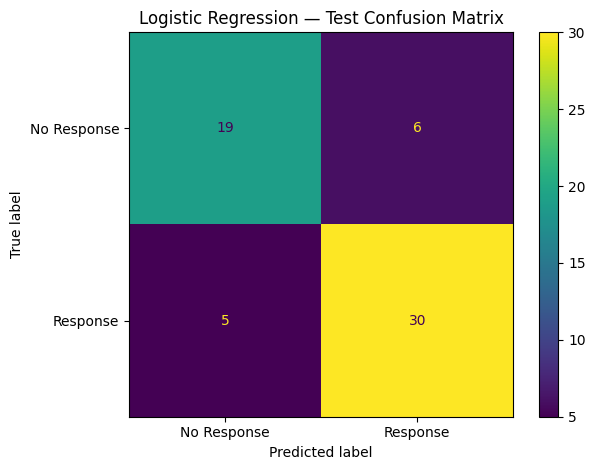

Classification threshold :  0.5
Undefined precision/recall values are handled using zero_division=0.


In [95]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

threshold = 0.5

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Response", "Response"])

disp.plot()
plt.title("Logistic Regression — Test Confusion Matrix")
plt.tight_layout()

plt.savefig("../outputs/figures/confusion_matrix.png", dpi=300)
plt.show()

print("Classification threshold : ", threshold)
print("Undefined precision/recall values are handled using zero_division=0.")

**Interpretation:** The model correctly identifies most responses, with 30 true positives and 19 true negatives. There are 6 false positives and 5 false negatives.

In [96]:
# Save supervised model results
model_metrics = pd.DataFrame({
    "model": ["Baseline", "Logistic Regression"],
    "accuracy": [accuracy_score(y_test, y_test_baseline), accuracy_score(y_test, y_test_pred)],
    "precision": [np.nan, precision_score(y_test, y_test_pred, zero_division=0)],
    "recall": [np.nan, recall_score(y_test, y_test_pred, zero_division=0)],
    "f1_score": [np.nan, f1_score(y_test, y_test_pred, zero_division=0)]})

model_metrics.to_csv("../outputs/model_metrics.csv", index=False)
holdout_predictions.to_csv("../outputs/test_predictions.csv", index=False)

print("Model metrics saved.")
print("Test predictions saved.")

model_metrics

Model metrics saved.
Test predictions saved.


,model,accuracy,precision,recall,f1_score
0,Baseline,0.583333,NaN,NaN,NaN
1,Logistic Regression,0.816667,0.833333,0.857143,0.84507


### S3 — Interpretation

- A false negative means a customer who would respond is predicted as non-responsive, so a possible campaign opportunity may be missed.
- A false positive means a non-responsive customer is predicted as responsive, which may lead to unnecessary campaign attention.
- The Logistic Regression results can be compared with the majority baseline using the test metrics. The 60-record test set is a single holdout, so the results have sampling uncertainty.


---

# Task 4 — Unsupervised Learning

K-Means is used here to find audience segments.

Clustering is performed only on the fit data using the transformed numeric predictors and `engineered_feature`. The `group` one-hot columns, response target and record ID are not used.


## U1 — K-Means and Selection

K-Means is tested for `k = 2, 3, 4`.

The models use `n_init=10` and `random_state=42`.
The highest silhouette score is selected, with the smaller k used if there is a tie.


In [97]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ["visits", "recency", "engagement", "spend", "engineered_feature"]

X_cluster = X_fit_final[cluster_features].copy()

results = []

for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_cluster)
    inertia = model.inertia_
    silhouette = silhouette_score(X_cluster, labels)

    results.append({"k": k,
                    "inertia": inertia,
                    "silhouette_score": silhouette})

cluster_scores = pd.DataFrame(results)
cluster_scores

,k,inertia,silhouette_score
0,2,713.030410,0.225909
1,3,613.551097,0.187178
2,4,541.645319,0.190736


In [98]:
# Select highest silhouette score
top_cluster_result = cluster_scores.sort_values(["silhouette_score", "k"], ascending=[False, True]).iloc[0]
chosen_k = int(top_cluster_result["k"])

print("Selected k : ", chosen_k)
print("Best silhouette score : ", top_cluster_result["silhouette_score"])

Selected k :  2
Best silhouette score :  0.22590949037480604


In [99]:
# Fit final K-Means using the selected k
final_clusterer = KMeans(n_clusters=chosen_k, n_init=10, random_state=42)

cluster_labels = final_clusterer.fit_predict(X_cluster)
clustered_fit = X_cluster.copy()
clustered_fit["cluster"] = cluster_labels

print("Selected k : ", chosen_k)
print("\nCluster counts : ")
print(clustered_fit["cluster"].value_counts().sort_index())

Selected k :  2

Cluster counts : 
cluster
0    109
1     83
Name: count, dtype: int64


In [100]:
cluster_scores.to_csv("../outputs/kmeans_diagnostics.csv", index=False)
clustered_fit.to_csv("../outputs/clustered_fit.csv", index=False)

print("K-Means diagnostics saved.")
print("Clustered fit data saved.")

K-Means diagnostics saved.
Clustered fit data saved.


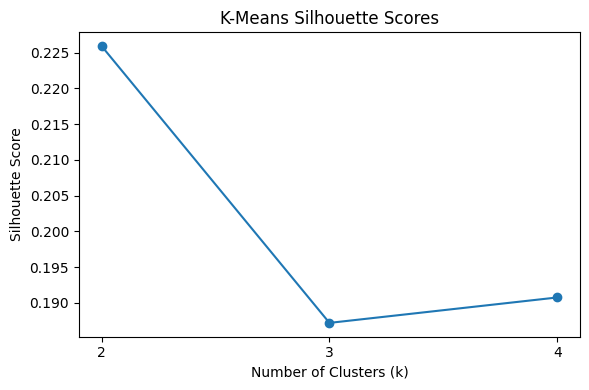

In [101]:
plt.figure(figsize=(6, 4))

plt.plot(cluster_scores["k"], cluster_scores["silhouette_score"], marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Scores")
plt.xticks([2, 3, 4])

plt.tight_layout()
plt.savefig("../outputs/figures/kmeans_silhouette.png", dpi=300)
plt.show()

**Interpretation:**

- K-Means was tested with k = 2, 3, and 4.
- The highest silhouette score is obtained with **k = 2**, so two audience segments are selected.
- The cluster selection is based only on the fit data and does not use the response target or test records.


## U2 — Segment Interpretation

The selected K-Means model is used to describe the audience segments using their feature profiles.

Cluster IDs are arbitrary labels and do not represent response classes.


In [102]:
# Cluster profile using original-scale values
profile_values = X_fit_numeric_imputed.copy()
profile_values["cluster"] = cluster_labels

cluster_sizes = (profile_values["cluster"].value_counts().sort_index())

print("Cluster sizes : ")
print(cluster_sizes)

print("\nCluster profiles : ")
print(profile_values.groupby("cluster").mean().round(2))

Cluster sizes : 
cluster
0    109
1     83
Name: count, dtype: int64

Cluster profiles : 
         visits  recency  engagement  spend  engineered_feature
cluster                                                        
0         49.37    55.25       46.09  50.18                0.83
1         49.54    44.17       57.45  50.97                1.29


In [103]:
segment_summary = (profile_values.groupby("cluster").mean().round(2))
segment_summary["records"] = cluster_sizes
segment_summary.to_csv("../outputs/cluster_profiles.csv")
segment_summary

,visits,recency,engagement,spend,engineered_feature,records
cluster,,,,,,
0,49.37,55.25,46.09,50.18,0.83,109
1,49.54,44.17,57.45,50.97,1.29,83


### U2 — Segment Interpretation

#### Cluster 0 — Lower Engagement Segment
- This group has lower average engagement and a lower engineered feature value.
- **Action:** Consider re-engagement or reminder campaigns for this segment.

#### Cluster 1 — Higher Engagement Segment
- This group has higher average engagement and a higher engineered feature value.
- **Action:** Consider relevant campaign offers or follow-up communication.

Cluster IDs are arbitrary labels assigned by K-Means and do not represent response classes.


---

# Task 5 — Deep Learning up to ANN

This section builds a small Artificial Neural Network to predict campaign response prediction.

The required architecture is:

`Input → Dense(16, ReLU) → Dense(8, ReLU) → Dense(1, Sigmoid)`

The ANN uses binary cross-entropy, Adam with learning rate 0.001, batch size 16, at most 50 epochs, and early stopping with patience 5.


## D1 — ANN Architecture and Compilation

A feed-forward ANN is created using the transformed features.
The sigmoid output is used because the response target is binary.


In [104]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

tf.random.set_seed(42)
np.random.seed(42)

ann_model = Sequential([Dense(16, activation="relu", input_shape=(X_fit_final.shape[1],)),
                        Dense(8, activation="relu"),
                        Dense(1, activation="sigmoid")])

ann_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy",
                  metrics=["accuracy"])

ann_model.summary()

print("Trainable parameters : ", ann_model.count_params())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters :  273


### D1 Explanation

The final sigmoid neuron produces a probability for response class 1.
Binary cross-entropy is suitable for the binary target, and Adam is used with the required learning rate of 0.001.


## D2 — Training and Validation

The ANN is trained on the 192 fit records for at most 50 epochs.

The reserved 48 validation records are used for early stopping. The best validation-loss weights are restored.


In [105]:
from tensorflow.keras.callbacks import EarlyStopping

# Early stopping
stop_training = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

# Train the ANN
history = ann_model.fit(X_fit_final, y_fit, validation_data=(X_val_final, y_val), epochs=50, batch_size=16, callbacks=[stop_training], verbose=1)

print("Actual epochs : ", len(history.history["loss"]))

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4740 - loss: 0.7370 - val_accuracy: 0.5625 - val_loss: 0.7358
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5104 - loss: 0.7113 - val_accuracy: 0.5833 - val_loss: 0.6968
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5521 - loss: 0.6902 - val_accuracy: 0.6250 - val_loss: 0.6632
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6146 - loss: 0.6710 - val_accuracy: 0.7708 - val_loss: 0.6327
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6562 - loss: 0.6525 - val_accuracy: 0.8750 - val_loss: 0.6050
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6771 - loss: 0.6354 - val_accuracy: 0.8750 - val_loss: 0.5808
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7135 - loss: 0.6186 - val_accuracy: 0.8958 - val_loss: 0.5581
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7240 - loss: 0.6016 - val_accuracy: 0.8958 - val_loss

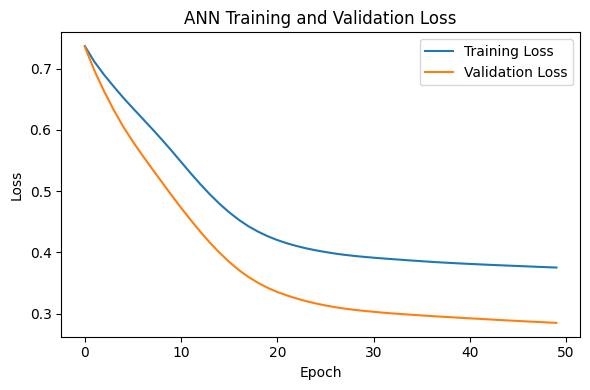

In [106]:
plt.figure(figsize=(6, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.savefig("../outputs/figures/ann_loss_curve.png", dpi=300)
plt.show()

**Interpretation:** Both training and validation loss decrease steadily, showing that the ANN is learning without clear signs of overfitting.

In [107]:
# Save ANN training information
training_summary = pd.DataFrame({"item": ["random_seed", "batch_size", "maximum_epochs", "patience", "actual_epochs", "best_validation_loss"],
                                  "value": [42, 16, 50, 5, len(history.history["loss"]), min(history.history["val_loss"])]})

training_summary.to_csv("../outputs/ann_training_info.csv", index=False)
training_summary


,item,value
0,random_seed,42.000000
1,batch_size,16.000000
2,maximum_epochs,50.000000
3,patience,5.000000
4,actual_epochs,50.000000
5,best_validation_loss,0.284662


**Interpretation:**

- Training and validation loss are compared to check the learning behaviour of the ANN.
- If validation loss starts increasing while training loss continues decreasing, this is a sign of overfitting.
- Early stopping restores the weights from the best validation-loss point.


## D3 — Comparison and Evidence

The ANN is evaluated on the same 60 test records using a threshold of 0.5.

Its accuracy, precision, recall and F1-score are compared with Logistic Regression.


In [108]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_test_proba_ann = ann_model.predict(X_test_final, verbose=0).ravel()

y_test_pred_ann = (y_test_proba_ann >= 0.5).astype(int)

# ANN metrics
ann_accuracy = accuracy_score(y_test, y_test_pred_ann)
ann_precision = precision_score(y_test, y_test_pred_ann, zero_division=0)
ann_recall = recall_score(y_test, y_test_pred_ann, zero_division=0)
ann_f1 = f1_score(y_test, y_test_pred_ann, zero_division=0)

print("ANN Test Metrics : ")
print("Accuracy : ", ann_accuracy)
print("Precision : ", ann_precision)
print("Recall : ", ann_recall)
print("F1-score : ", ann_f1)

ANN Test Metrics : 
Accuracy :  0.85
Precision :  0.8611111111111112
Recall :  0.8857142857142857
F1-score :  0.8732394366197183


In [109]:
# Logistic Regression metrics
logreg_accuracy = accuracy_score(y_test, y_test_pred)
logreg_precision = precision_score(y_test, y_test_pred, zero_division=0)
logreg_recall = recall_score(y_test, y_test_pred, zero_division=0)
logreg_f1 = f1_score(y_test, y_test_pred, zero_division=0)

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "ANN"],
    "Accuracy": [logreg_accuracy, ann_accuracy],
    "Precision": [logreg_precision, ann_precision],
    "Recall": [logreg_recall, ann_recall],
    "F1-score": [logreg_f1, ann_f1]})

model_comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.816667,0.833333,0.857143,0.845070
1,ANN,0.850000,0.861111,0.885714,0.873239


In [110]:
# Save final model comparison
model_comparison.to_csv("../outputs/final_model_comparison.csv", index=False)

# Save ANN predictions
ann_predictions = test[["record_id"]].copy()

ann_predictions["true_label"] = y_test.values
ann_predictions["predicted_label"] = y_test_pred_ann
ann_predictions["class_1_probability"] = y_test_proba_ann

ann_predictions.to_csv("../outputs/ann_test_predictions.csv", index=False)

print("Final comparison saved.")
print("ANN predictions saved.")

Final comparison saved.
ANN predictions saved.


In [111]:
# Saving trained ANN
ann_model.save("../models/ann_model.keras")

print("ANN model saved.")

ANN model saved.


### D3 Interpretation

The final model comparison should be based on the same untouched test records and the same 0.5 classification threshold.

F1-score is useful here because it combines precision and recall for the response class. The ANN does not need to outperform Logistic Regression; the comparison should be based on the observed holdout results and the simplicity of the models.


# Final Checks

All five required technical modules are included in this notebook.

### Required evidence saved
- `outputs/splits.csv`
- `outputs/statistics_summary.csv`
- `outputs/inference_results.csv`
- `outputs/covariance_matrix.csv`
- `outputs/eigenvalues.csv`
- `outputs/preprocessing_audit.csv`
- `outputs/model_metrics.csv`
- `outputs/test_predictions.csv`
- `outputs/kmeans_diagnostics.csv`
- `outputs/cluster_profiles.csv`
- `outputs/final_model_comparison.csv`
- `outputs/ann_test_predictions.csv`
- `outputs/figures/engagement_histogram.png`
- `outputs/figures/confusion_matrix.png`
- `outputs/figures/kmeans_silhouette.png`
- `outputs/figures/ann_loss_curve.png`
- `models/preprocessing.joblib`
- `models/ann_model.keras`

The supplied raw CSV and `generate_data.py` are not modified.


In [112]:
# Final file check
from pathlib import Path

required_files = [
    "../outputs/splits.csv",
    "../outputs/statistics_summary.csv",
    "../outputs/inference_results.csv",
    "../outputs/covariance_matrix.csv",
    "../outputs/eigenvalues.csv",
    "../outputs/preprocessing_audit.csv",
    "../outputs/model_metrics.csv",
    "../outputs/test_predictions.csv",
    "../outputs/kmeans_diagnostics.csv",
    "../outputs/cluster_profiles.csv",
    "../outputs/final_model_comparison.csv",
    "../outputs/ann_test_predictions.csv",
    "../outputs/figures/engagement_histogram.png",
    "../outputs/figures/confusion_matrix.png",
    "../outputs/figures/kmeans_silhouette.png",
    "../outputs/figures/ann_loss_curve.png",
    "../models/preprocessing.joblib",
    "../models/ann_model.keras"
]

for file in required_files:
    print("✓" if Path(file).exists() else "○", file)

✓ ../outputs/splits.csv
✓ ../outputs/statistics_summary.csv
✓ ../outputs/inference_results.csv
✓ ../outputs/covariance_matrix.csv
✓ ../outputs/eigenvalues.csv
✓ ../outputs/preprocessing_audit.csv
✓ ../outputs/model_metrics.csv
✓ ../outputs/test_predictions.csv
✓ ../outputs/kmeans_diagnostics.csv
✓ ../outputs/cluster_profiles.csv
✓ ../outputs/final_model_comparison.csv
✓ ../outputs/ann_test_predictions.csv
✓ ../outputs/figures/engagement_histogram.png
✓ ../outputs/figures/confusion_matrix.png
✓ ../outputs/figures/kmeans_silhouette.png
✓ ../outputs/figures/ann_loss_curve.png
✓ ../models/preprocessing.joblib
✓ ../models/ann_model.keras


---